# Figures to accompany in vivo fMRS data

## Statistical results - paired t-test

In [1]:
import pandas as pd
from pathlib import Path
fixed_path = Path('group_results') / 'fixed_paired'
var_path = Path('group_results') / 'var_paired'

group_stats_fixed = pd.read_csv(fixed_path / 'group_stats.csv', index_col=0, header=[0, 1])
group_stats_var = pd.read_csv(var_path / 'group_stats.csv', index_col=0, header=[0, 1])

In [2]:
combined_peaks = ['NAA', 'NAAG', 'Cr', 'PCr', 'PCho', 'GPC']

format = {
    ('COPE', 'STIM>CTRL'): '{:.2e}',
    ('COPE', 'CTRL>STIM'): '{:.2e}',
    ('VARCOPE', 'STIM>CTRL'): '{:.2e}',
    ('VARCOPE', 'CTRL>STIM'): '{:.2e}',
}
def style_sig(v, props=''):
    return props if v < 0.05 else None
def filter_results(res_df):
    filtered = res_df.filter(regex=r'.*_mean_activation', axis=0)
    filtered = filtered.drop([f'conc_{x}_mean_activation' for x in combined_peaks])
    filtered.index = filtered.index.str.replace('conc_', '')
    filtered.index = filtered.index.str.replace('_mean_activation', '')
    return filtered.style\
        .format(format, precision=2)\
        .applymap(style_sig, props='color:red;', subset='p')

filter_results(group_stats_fixed)

In [3]:
filter_results(group_stats_var)

In [4]:
def filter_lw(res_df):
    filtered = res_df.filter(regex=r'(sigma_0)|(gamma_0)', axis=0)
    return filtered.style\
        .format(format, precision=2)\
        .applymap(style_sig, props='color:red;', subset='p')

filter_lw(group_stats_fixed)

In [5]:
filter_lw(group_stats_var)

## Visualisation - group means

### Load all the datasets

In [6]:
var_path = Path('group_results') / 'var_group_mean'
group_mean_var = pd.read_csv(var_path / 'group_stats.csv', index_col=0, header=[0, 1])

fixed_path = Path('group_results') / 'fixed_group_mean'
group_mean_fixed = pd.read_csv(fixed_path / 'group_stats.csv', index_col=0, header=[0, 1])

def filter_mean(df):
    mean_filtered = df\
        .filter(regex=r'conc_[\w+]*_((STIM\d{1})|(linear)|(constant))', axis=0)\
        .filter(like='COPE')\
        .filter(like='+ve')\
        .rename(index=lambda x: x.replace('conc_', ''))\
        .rename(columns=lambda x: x.replace(' +ve', ''))\
        .reorder_levels([1, 0], axis=1)
    mean_filtered.index = mean_filtered.index.str.split('_', expand=True)
    return mean_filtered.sort_index(axis=1)

filtered_var = filter_mean(group_mean_var)
filtered_fix = filter_mean(group_mean_fixed)


per_sub_df = {f'P{x:03.0f}': [] for x in range(1, 14)}
for file in var_path.rglob('free_parameters.csv'):
    curr_df = pd.read_csv(file, index_col=0, header=[0])
    curr_df.sd = curr_df.sd.pow(2)
    idx, pt = file.parent.name.split('_')
    if int(idx) < 13:
        curr_df = pd.concat({'open': curr_df.T}, names=['Contrasts']).T
        per_sub_df[pt].append(curr_df)
    else:
        curr_df = pd.concat({'closed': curr_df.T}, names=['Contrasts']).T
        per_sub_df[pt].append(curr_df)

def filter_single(df):
    filtered = df.filter(regex=r'conc_[\w+]*_((STIM\d{1})|(linear)|(constant))', axis=0)\
        .rename(index=lambda x: x.replace('conc_', ''))\
        .rename(columns={'mean': 'COPE', 'sd': 'VARCOPE'})
    filtered.index = filtered.index.str.split('_', expand=True)
    return filtered

for key, item in per_sub_df.items():
    per_sub_df[key] = filter_single(pd.concat(item, axis=1))


In [7]:
filtered_var.loc['Glu', 'open'].VARCOPE

STIM0       0.000103
STIM1       0.000070
STIM2       0.000111
STIM3       0.000158
linear      0.000345
constant    0.000120
Name: VARCOPE, dtype: float64

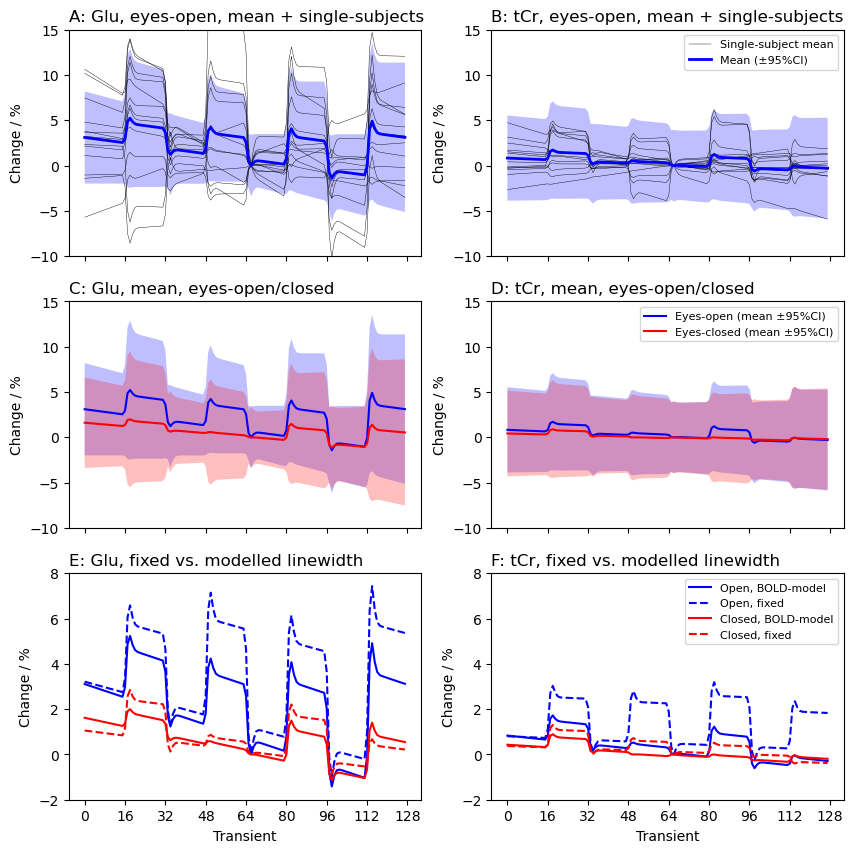

In [9]:
designmat = pd.read_csv('design_matrix.csv', header=None)

def generate_traces(filt_df, metab, condition, rel=False):
    mean_df = filt_df.loc[metab, condition].COPE
    mean = designmat.to_numpy() @ mean_df.to_numpy()

    sd_df = filt_df.loc[metab, condition].VARCOPE.pow(0.5)
    sd = np.abs(designmat.to_numpy()) @ sd_df.to_numpy()
    ci = sd * 1.96
    if rel:
        mean_perc = mean / mean_df.constant
        mean_perc -= mean_perc[66]
        mean_perc *= 100
        ci_perc = 100 * ci / mean_df.constant
        return mean_perc, mean_perc + ci_perc, mean_perc - ci_perc
    else:
        return mean, mean + ci, mean - ci

import  matplotlib.pyplot as plt
import numpy as np

def plot_trace(df, metab, condition, ax, var=False, color='k', lw=1.5, style='-', label=None):
    mean, pos_err, neg_err = generate_traces(
        df,
        metab,
        condition,
        True)

    x_fill = np.arange(0,128).tolist()+np.flip(np.arange(0, 128)).tolist()
    y_fill = pos_err.tolist() + np.flip(neg_err).tolist()
    if var:
        ax.fill_between(x_fill, y_fill, alpha=0.25, facecolor=color)
    ax.plot(mean, color, linewidth=lw, linestyle=style, label=label)

fig, axes = plt.subplots(3, 2, figsize=(10,10), sharex=True)

metab1 = "Glu"
metab2 = "Cr+PCr"

# First panel (Glu with single subjects)
for sub in per_sub_df:
    plot_trace(per_sub_df[sub], metab1, 'open', axes[0][0], var=False, color='k', lw=0.3)
plot_trace(filtered_var, metab1, 'open', axes[0][0], var=True, color='b', lw=2)


# second panel (tNAA with single subjects)
for idx, sub in enumerate(per_sub_df):
    if idx == 0:
        plot_trace(per_sub_df[sub], metab2, 'open', axes[0][1], var=False, color='k', lw=0.3, label='Single-subject mean')
    else:
        plot_trace(per_sub_df[sub], metab2, 'open', axes[0][1], var=False, color='k', lw=0.3)
plot_trace(filtered_var, metab2, 'open', axes[0][1], var=True, color='b', lw=2, label='Mean (±95%CI)')


# third panel (Glu opne/closed)
plot_trace(filtered_var, metab1, 'open', axes[1][0], var=True, color='b')
plot_trace(filtered_var, metab1, 'closed', axes[1][0], var=True, color='r')

# Fourth panel (tNAA opne/closed)
plot_trace(filtered_var, metab2, 'open', axes[1][1], var=True, color='b', label='Eyes-open (mean ±95%CI)')
plot_trace(filtered_var, metab2, 'closed', axes[1][1], var=True, color='r', label='Eyes-closed (mean ±95%CI)')


# Fifth panel (Glu var/fixed)
plot_trace(filtered_var, metab1, 'open', axes[2][0], var=False, color='b', label='Open, variable')
plot_trace(filtered_fix, metab1, 'open', axes[2][0], var=False, color='b', style='--', label='Open, fixed')
plot_trace(filtered_var, metab1, 'closed', axes[2][0], var=False, color='r', label='Closed, variable')
plot_trace(filtered_fix, metab1, 'closed', axes[2][0], var=False, color='r', style='--', label='Closed, fixed')

plot_trace(filtered_var, metab2, 'open', axes[2][1], var=False, color='b', label='Open, BOLD-model')
plot_trace(filtered_fix, metab2, 'open', axes[2][1], var=False, color='b', style='--', label='Open, fixed')
plot_trace(filtered_var, metab2, 'closed', axes[2][1], var=False, color='r', label='Closed, BOLD-model')
plot_trace(filtered_fix, metab2, 'closed', axes[2][1], var=False, color='r', style='--', label='Closed, fixed')

for ax in axes.ravel():
    ax.set_ylim([-10, 15])
    ax.set_ylabel('Change / %')
    ax.set_xticks(np.arange(0,129,16))

axes[2][0].set_ylim([-2, 8])
axes[2][1].set_ylim([-2, 8])

axes[2][0].set_xlabel('Transient')
axes[2][1].set_xlabel('Transient')

axes[0][0].set_title('A: Glu, eyes-open, mean + single-subjects', fontsize=12, loc='left')
axes[0][1].set_title('B: tCr, eyes-open, mean + single-subjects', fontsize=12, loc='left')
axes[1][0].set_title('C: Glu, mean, eyes-open/closed', fontsize=12, loc='left')
axes[1][1].set_title('D: tCr, mean, eyes-open/closed', fontsize=12, loc='left')
axes[2][0].set_title('E: Glu, fixed vs. modelled linewidth', fontsize=12, loc='left')
axes[2][1].set_title('F: tCr, fixed vs. modelled linewidth', fontsize=12, loc='left')

axes[0][1].legend(fontsize=8, loc='upper right')
axes[1][1].legend(fontsize=8, loc='upper right')
axes[2][1].legend(fontsize=8, loc='upper right')

plt.savefig('../../publication/figures/fig6_invivo_fmrs.png', dpi=400, bbox_inches='tight', transparent=True)
